# Notebook 04
* Author: Melissa Ormeño
* Date: May 2024

Aims:
* Obiene las mutaciones por tipo de cancer ya clasificadas por su frecuencia de alelo mutante
* Grafica el numero de mutaciones por gen y por tipo de cancer

In [2]:
# Dependences
import pandas as pd
import altair as alt

# Step1: Obtener data frame que contenga los aminoacidos mutados

In [3]:
# DF obtenido del notebook 03
# Contiene la data clasificada por frecuencia de alelo mutante
# Datos con la lista de genes quinasa a trabajar 
#interpro_code = 'IPR000333'
family_name = 'STKR'
df = pd.read_csv('../data/mutaciones/df_frecuencias_mut_{0}.csv'.format(family_name))
print(df.shape)
print(df.columns)
df.head(2)

(3121, 14)
Index(['Gen_names', 'icgc_donor_id', 'aa_mutation', 'cds_mutation',
       'mutated_from_allele', 'mutated_to_allele', 'consequence_type',
       'project_code', 'tipo_cancer', 'total_read_count',
       'mutant_allele_read_count', 'mutant_allele_frequency',
       '%mutant_allele_frequency', 'clasificacion'],
      dtype='object')


,Gen_names,icgc_donor_id,aa_mutation,cds_mutation,mutated_from_allele,mutated_to_allele,consequence_type,project_code,tipo_cancer,total_read_count,mutant_allele_read_count,mutant_allele_frequency,%mutant_allele_frequency,clasificacion
0,BMPR1A,DO28154,K372I,1115A>T,A,T,missense_variant,OV-US,Ovario,344.0,9.0,0.026163,2.616279,Baja frecuencia
1,TGFBR1,DO23786,S416F,1247C>T,C,T,missense_variant,LUAD-US,Pulmon,358.0,10.0,0.027933,2.793296,Baja frecuencia


In [4]:
df['aa_mutation'].nunique()

2606

In [5]:
#Elimina todas las columnas repetidas
df_cancer = df.drop_duplicates(subset=['Gen_names', 'icgc_donor_id', 'aa_mutation', 'cds_mutation',
       'mutated_from_allele', 'mutated_to_allele', 'consequence_type',
       'project_code', 'tipo_cancer', 'total_read_count',
       'mutant_allele_read_count', 'mutant_allele_frequency',
       '%mutant_allele_frequency', 'clasificacion'])

df_cancer.shape

(3121, 14)

In [6]:
df_cancer[['aa_mutation', 'tipo_cancer']].nunique()

aa_mutation    2606
tipo_cancer      17
dtype: int64

In [7]:
df_cancer['tipo_cancer'].unique()

array(['Ovario', 'Pulmon', 'Estomago', 'Pancreas', 'Colon', 'Cerebro',
       'Seno ', 'Prostata', 'Vejiga', 'Riñon', 'Sangre', 'Cabeza',
       'Higado', 'Piel', 'Utero', 'Gladd', 'Cervix'], dtype=object)

In [8]:
df_mut = df_cancer[['tipo_cancer','aa_mutation','Gen_names']]
df_mut

,tipo_cancer,aa_mutation,Gen_names
0,Ovario,K372I,BMPR1A
1,Pulmon,S416F,TGFBR1
2,Pulmon,S347F,TGFBR1
3,Pulmon,S339F,TGFBR1
4,Pulmon,S420F,TGFBR1
...,...,...,...
3116,Cervix,Q22*,BMPR1A
3117,Piel,S233F,BMPR2
3118,Pancreas,C98Y,TGFBR1
3119,Pancreas,C101Y,TGFBR1


In [9]:
# Paso 1: Eliminar duplicados por paciente y gen, pero considerando solo mutaciones únicas por gen y paciente
df_unique = df_cancer.drop_duplicates(subset=['Gen_names', 'aa_mutation'])

# Paso 2: Contar la frecuencia de mutación por gen (mutaciones únicas por paciente)
mutation_frequencies = df_unique.groupby('Gen_names').size().reset_index(name='mutation_count')

# Paso 3: Contar el número total de pacientes
total_patients = df_cancer['icgc_donor_id'].nunique()

# Paso 4: Calcular la frecuencia de mutación como la proporción de mutaciones por gen al número total de pacientes
mutation_frequencies['mutation_frequency'] = mutation_frequencies['mutation_count'] / total_patients

# Paso 5: Mostrar los resultados
mutation_frequencies.sort_values(ascending=False, by='mutation_count')

,Gen_names,mutation_count,mutation_frequency
10,TGFBR1,437,0.432673
1,ACVR1B,361,0.357426
5,ACVRL1,320,0.316832
2,ACVR1C,315,0.311881
11,TGFBR2,244,0.241584
3,ACVR2A,229,0.226733
8,BMPR1B,192,0.190099
9,BMPR2,176,0.174257
6,AMHR2,157,0.155446
0,ACVR1,90,0.089109


In [10]:
total_patients

1010

In [11]:
df_tgfbr1 = df_unique[df_unique['Gen_names']=='TGFBR1']
len(df_tgfbr1)

437

In [25]:
# Paso 1: Eliminar duplicados por paciente y gen, pero considerando solo mutaciones únicas por gen y paciente
df_unique = df_cancer.drop_duplicates(subset=['aa_mutation','tipo_cancer','Gen_names'])

# Paso 2: Contar la frecuencia de mutación por gen (mutaciones únicas por paciente)
mutation_frequencies_cancer_type = df_unique.groupby(['tipo_cancer', 'Gen_names']).size().reset_index(name='mutation_count')

# Paso 3: Contar el número total de pacientes
total_patients = df_cancer['icgc_donor_id'].nunique()

# Paso 4: Calcular la frecuencia de mutación como la proporción de mutaciones por gen al número total de pacientes
mutation_frequencies_cancer_type['mutation_frequency'] = mutation_frequencies_cancer_type['mutation_count'] / total_patients

# Paso 5: Mostrar los resultados
mutation_frequencies_cancer_type.sort_values(ascending=False, by='mutation_count')

,tipo_cancer,Gen_names,mutation_count,mutation_frequency
172,Utero,TGFBR1,118,0.116832
164,Utero,ACVR1C,91,0.090099
42,Colon,TGFBR1,86,0.085149
163,Utero,ACVR1B,84,0.083168
103,Piel,ACVRL1,72,0.071287
...,...,...,...,...
113,Prostata,ACVR2B,1,0.000990
177,Vejiga,ACVR2A,1,0.000990
154,Seno,ACVR2B,1,0.000990
95,Pancreas,BMPR2,1,0.000990


In [26]:
# Assuming the DataFrame mutation_frequencies is already defined and populated with data

# Saving the mutation_frequencies DataFrame to an Excel file
file_path = 'mutation_frequencies.xlsx'
mutation_frequencies_cancer_type.to_excel(file_path, index=False)

file_path  # Return the file path for the user to download the file


'mutation_frequencies.xlsx'

In [27]:
total_patients

1010

In [28]:
df_cancer['aa_mutation'].nunique()

2606

In [29]:
df_unique.sort_values(by='aa_mutation', ascending=True).head(20)

,Gen_names,icgc_donor_id,aa_mutation,cds_mutation,mutated_from_allele,mutated_to_allele,consequence_type,project_code,tipo_cancer,total_read_count,mutant_allele_read_count,mutant_allele_frequency,%mutant_allele_frequency,clasificacion
1279,ACVR1C,DO43907,*337Y,1011A>C,T,G,stop_lost,UCEC-US,Utero,32.0,7.0,0.218750,21.875000,Media frecuencia
1277,ACVR1C,DO43907,*414Y,1242A>C,T,G,stop_lost,UCEC-US,Utero,32.0,7.0,0.218750,21.875000,Media frecuencia
1278,ACVR1C,DO43907,*444Y,1332A>C,T,G,stop_lost,UCEC-US,Utero,32.0,7.0,0.218750,21.875000,Media frecuencia
1413,ACVR1B,DO40855,*454Y,1362A>C,A,C,stop_lost,UCEC-US,Utero,38.0,9.0,0.236842,23.684211,Media frecuencia
2102,AMHR2,DO49763,*479*,1436G>A,G,A,stop_retained_variant,BLCA-US,Vejiga,82.0,28.0,0.341463,34.146341,Media frecuencia
2801,AMHR2,DO43578,*479Y,1437A>C,A,C,stop_lost,UCEC-US,Utero,32.0,15.0,0.468750,46.875000,Alta frecuencia
1276,ACVR1C,DO43907,*494Y,1482A>C,T,G,stop_lost,UCEC-US,Utero,32.0,7.0,0.218750,21.875000,Media frecuencia
1410,ACVR1B,DO40855,*506Y,1518A>C,A,C,stop_lost,UCEC-US,Utero,38.0,9.0,0.236842,23.684211,Media frecuencia
1409,ACVR1B,DO40855,*547Y,1641A>C,A,C,stop_lost,UCEC-US,Utero,38.0,9.0,0.236842,23.684211,Media frecuencia
2802,AMHR2,DO43578,*574Y,1722A>C,A,C,stop_lost,UCEC-US,Utero,32.0,15.0,0.468750,46.875000,Alta frecuencia


In [30]:
df_cancer[df_cancer['aa_mutation']=='K372I']

,Gen_names,icgc_donor_id,aa_mutation,cds_mutation,mutated_from_allele,mutated_to_allele,consequence_type,project_code,tipo_cancer,total_read_count,mutant_allele_read_count,mutant_allele_frequency,%mutant_allele_frequency,clasificacion
0,BMPR1A,DO28154,K372I,1115A>T,A,T,missense_variant,OV-US,Ovario,344.0,9.0,0.026163,2.616279,Baja frecuencia
2567,BMPR1B,DO41644,K372I,1115A>T,A,T,missense_variant,UCEC-US,Utero,50.0,21.0,0.420000,42.000000,Media frecuencia


In [31]:
mutation_frequencies.sort_values(by='mutation_count',ascending=False)


,Gen_names,mutation_count,mutation_frequency
10,TGFBR1,437,0.432673
1,ACVR1B,361,0.357426
5,ACVRL1,320,0.316832
2,ACVR1C,315,0.311881
11,TGFBR2,244,0.241584
3,ACVR2A,229,0.226733
8,BMPR1B,192,0.190099
9,BMPR2,176,0.174257
6,AMHR2,157,0.155446
0,ACVR1,90,0.089109


In [32]:
mutation_frequencies.sort_values(by='mutation_count',ascending=False)

,Gen_names,mutation_count,mutation_frequency
10,TGFBR1,437,0.432673
1,ACVR1B,361,0.357426
5,ACVRL1,320,0.316832
2,ACVR1C,315,0.311881
11,TGFBR2,244,0.241584
3,ACVR2A,229,0.226733
8,BMPR1B,192,0.190099
9,BMPR2,176,0.174257
6,AMHR2,157,0.155446
0,ACVR1,90,0.089109


In [33]:

# Crear el histograma
gen_freq=alt.Chart(mutation_frequencies).mark_bar(
        ).encode(
            x=alt.X('Gen_names', title='Mutación AA', sort='-y'),
            y=alt.Y('sum(mutation_frequency):Q', title='Frecuencia'),
            color=alt.Color(scale=alt.Scale(scheme='category20')),
            tooltip=['Gen_names', 'mutation_frequency', 'mutation_count']
        ).properties(
            title='Frecuencia de mutacion por Gen',
            width=300,
        height=150
            )
cancer_freq=alt.Chart(mutation_frequencies_cancer_type).mark_bar(
        ).encode(
            x=alt.X('tipo_cancer', title='Mutación AA', sort='-y'),
            y=alt.Y('sum(mutation_frequency):Q', title='Frecuencia'),
            color=alt.Color(scale=alt.Scale(scheme='category20')),
            tooltip=['tipo_cancer', 'mutation_count','mutation_frequency']
        ).properties(
            title='Frecuencia de mutaciones por Tipo de Cáncer',
            width=300,
            height=150
        )
gen_freq|cancer_freq

alt.HConcatChart(...)

In [34]:
# Agrupar por consequence_type y contar el número de mutaciones únicas
mutation_counts = df_cancer.groupby('consequence_type')['aa_mutation'].nunique().reset_index(name='num_mutaciones')

# Ordenar por el número de mutaciones de forma descendente
mutation_counts = mutation_counts.sort_values(by='num_mutaciones', ascending=False)

# Imprimir el número de mutaciones para cada consequence_type
for index, row in mutation_counts.iterrows():
    print(f"Número de mutaciones {row['consequence_type']}: {row['num_mutaciones']}")

# Crear el histograma
base = alt.Chart(df_cancer).transform_aggregate(
    unique_aa_mutation='distinct(aa_mutation)',
    groupby=['consequence_type','aa_mutation']
         ).mark_bar(
        ).encode(
            x=alt.X('consequence_type', title='Mutación AA', sort='-y',axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
            y=alt.Y('count(unique_aa_mutarion):Q', title='Frecuencia'),
            color=alt.Color(scale=alt.Scale(scheme='category20')),
            tooltip=['consequence_type', 'count()'],
            text =  'count(unique_aa_mutarion):Q'
        ).properties(
            title='Frecuencia de mutacion por Gen',
            width=300,
        height=150
            )
base.mark_bar() + base.mark_text(align='center', dx=2)

Número de mutaciones missense_variant: 2313
Número de mutaciones stop_gained: 280
Número de mutaciones stop_lost: 9
Número de mutaciones start_lost: 3
Número de mutaciones stop_retained_variant: 1


alt.LayerChart(...)

In [35]:
mutation_frequencies_cancer_type

,tipo_cancer,Gen_names,mutation_count,mutation_frequency
0,Cabeza,ACVR1,5,0.004950
1,Cabeza,ACVR1B,19,0.018812
2,Cabeza,ACVR1C,27,0.026733
3,Cabeza,ACVR2A,5,0.004950
4,Cabeza,ACVR2B,3,0.002970
...,...,...,...,...
181,Vejiga,BMPR1A,2,0.001980
182,Vejiga,BMPR1B,12,0.011881
183,Vejiga,BMPR2,11,0.010891
184,Vejiga,TGFBR1,32,0.031683


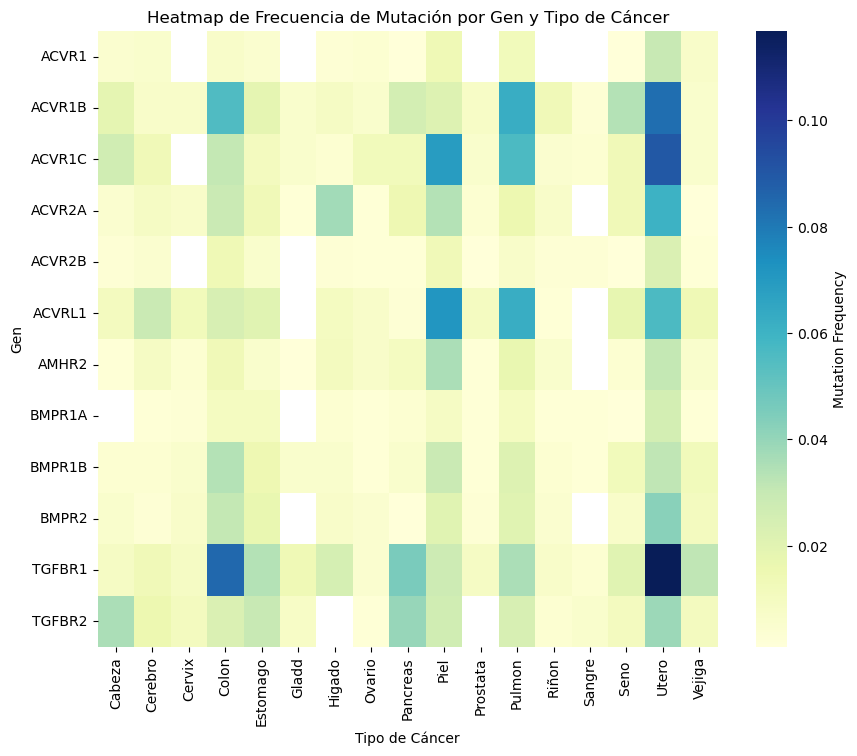

In [36]:
import seaborn as sns
import matplotlib.pyplot as plt

# Ordenar el DataFrame por 'mutation_count' de mayor a menor
heatmap = mutation_frequencies_cancer_type.sort_values(by='mutation_frequency', ascending=True)

# Crear el DataFrame pivotado para el heatmap (index: Gen_names, columns: tipo_cancer, values: mutation_frequency)
heatmap_data = heatmap.pivot(index='Gen_names', columns="tipo_cancer", values="mutation_frequency")

# Crear el heatmap usando seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_data, annot=False, cmap="YlGnBu", cbar_kws={'label': 'Mutation Frequency'})

# Añadir título y etiquetas
plt.title("Heatmap de Frecuencia de Mutación por Gen y Tipo de Cáncer")
plt.xlabel("Tipo de Cáncer")
plt.ylabel("Gen")

# Guardar el gráfico en formato SVG
# plt.savefig("heatmap_mutation_frequency.svg", format='svg')

# Mostrar el gráfico
plt.show()


In [38]:
ordered_genes = mutation_frequencies_cancer_type.groupby('Gen_names')['mutation_count'].sum().sort_values(ascending=False).index
ordered_genes

Index(['TGFBR1', 'ACVR1B', 'ACVR1C', 'ACVRL1', 'TGFBR2', 'ACVR2A', 'BMPR1B',
       'BMPR2', 'AMHR2', 'ACVR1', 'BMPR1A', 'ACVR2B'],
      dtype='object', name='Gen_names')

In [39]:
import altair as alt
import pandas as pd

# Asegúrate de que los genes estén ordenados por la suma de mutaciones
ordered_genes = mutation_frequencies_cancer_type.groupby('Gen_names')['mutation_count'].sum().sort_values(ascending=False).index
ordered_cancer = mutation_frequencies_cancer_type.groupby('tipo_cancer')['mutation_count'].sum().sort_values(ascending=False).index
# Configurar el gráfico base con el orden de genes
base = alt.Chart(mutation_frequencies_cancer_type).encode(
    x=alt.X('tipo_cancer', sort=list(ordered_cancer)),
    y=alt.Y('Gen_names', sort=list(ordered_genes)),  # Ordenar los genes de mayor a menor según mutation_count
)

# Configurar el heatmap
heatmap = base.mark_rect().encode(
    color=alt.Color('mutation_count',
        scale=alt.Scale(scheme='viridis'),
        legend=alt.Legend(title="Total de Mutaciones"),
    ), 
    tooltip=[
        alt.Tooltip("sum(mutation_count)", title="Total de Mutaciones"),
        alt.Tooltip("tipo_cancer", title="Tipo de Cáncer"),
        alt.Tooltip("mutation_frequency", title="frecuencia")
    ]
)

# Configurar el texto dentro de las celdas del heatmap
text = base.mark_text(baseline='middle').encode(
    text=alt.Text('sum(mutation_count)', format=".0f"),
    color=alt.condition(
        alt.datum.mutation_count > 150,
        alt.value('black'),
        alt.value('white')
    )
)

# Dibujar el gráfico
heatmap + text


alt.LayerChart(...)

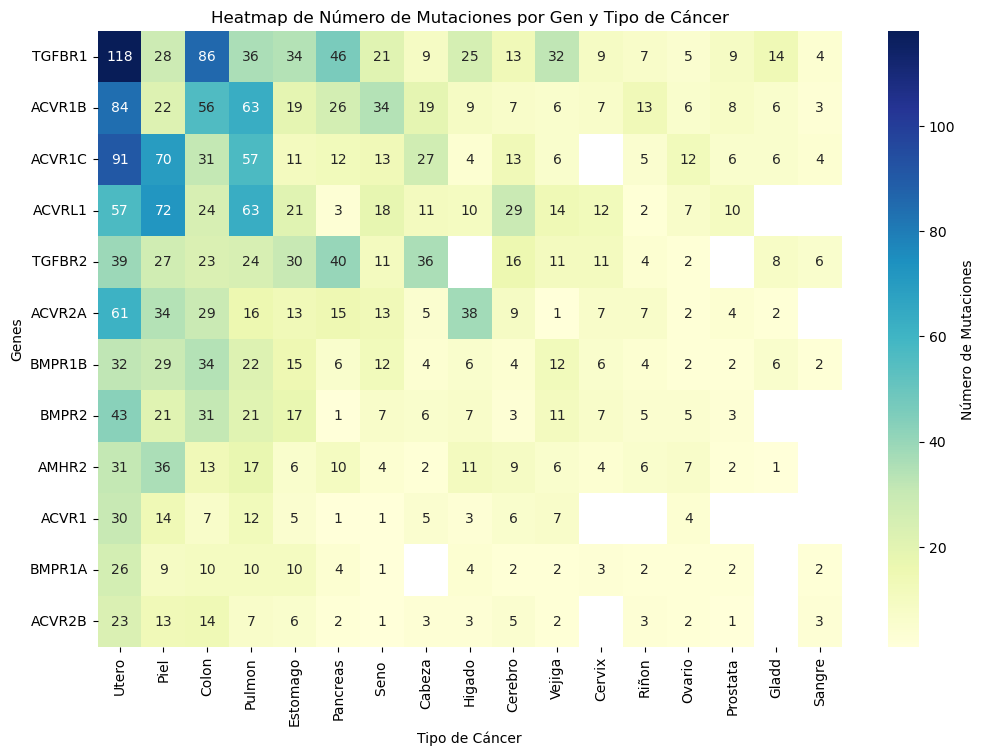

In [40]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Asegúrate de que los genes y tipos de cáncer estén ordenados por la suma de mutaciones
ordered_genes = mutation_frequencies_cancer_type.groupby('Gen_names')['mutation_count'].sum().sort_values(ascending=False).index
ordered_cancer = mutation_frequencies_cancer_type.groupby('tipo_cancer')['mutation_count'].sum().sort_values(ascending=False).index

# Pivotear el DataFrame para que quede en formato adecuado para el heatmap
heatmap_data = mutation_frequencies_cancer_type.pivot_table(
    index='Gen_names',
    columns='tipo_cancer',
    values='mutation_count',
    aggfunc='sum'  # Asegúrate de que se agregue la frecuencia por gen y tipo de cáncer
).reindex(index=ordered_genes, columns=ordered_cancer)

# Crear el heatmap usando seaborn
plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, cmap="YlGnBu", annot=True, fmt=".0f", cbar_kws={'label': 'Número de Mutaciones'})

# Añadir título y etiquetas
plt.title("Heatmap de Número de Mutaciones por Gen y Tipo de Cáncer")
plt.xlabel("Tipo de Cáncer")
plt.ylabel("Genes")

# Guardar el gráfico en formato SVG antes de mostrarlo
#plt.savefig("../run/imagenes/heatmap_mutation_number_{0}.svg".format(family_name), format='svg')

# Mostrar el gráfico
plt.show()



In [41]:
ordered_cancer

Index(['Utero', 'Piel', 'Colon', 'Pulmon', 'Estomago', 'Pancreas', 'Seno ',
       'Cabeza', 'Higado', 'Cerebro', 'Vejiga', 'Cervix', 'Riñon', 'Ovario',
       'Prostata', 'Gladd', 'Sangre'],
      dtype='object', name='tipo_cancer')

In [ ]:
df_unique.groupby('Gen_names')['mutant_allele_frequency'].sum().sort_values(ascending=False)

In [ ]:
ordered_cancer = df_unique.groupby('Gen_names')['mutant_allele_frequency'].sum().sort_values(ascending=False).index
ordered_cancer

In [ ]:
df_unique.sort_values(by='%mutant_allele_frequency',ascending=False)



In [ ]:

import matplotlib.pyplot as plt
import pandas as pd

# Asegúrate de que los genes y tipos de cáncer estén ordenados por la suma de mutaciones
ordered_genes = df_unique.groupby('Gen_names')['mutant_allele_frequency'].sum().sort_values(ascending=False).index
ordered_cancer = df_unique.groupby('tipo_cancer')['mutant_allele_frequency'].sum().sort_values(ascending=False).index
import seaborn as sns

# Pivotear el DataFrame para que quede en formato adecuado para el heatmap
heatmap_data = df_unique.pivot_table(
    index='Gen_names',
    columns='tipo_cancer',
    values='mutant_allele_frequency',
    aggfunc='sum'
 # Asegúrate de que se agregue la frecuencia por gen y tipo de cáncer
).reindex(index=ordered_genes, columns=ordered_cancer)

# Crear el heatmap usando seaborn
plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, cmap="YlGnBu", annot=True, fmt=".0f", cbar_kws={'label': 'Frecuencia de Mutaciones'})

# Añadir título y etiquetas
plt.title("Heatmap de Frecuencia de alelo mutante por Gen y Tipo de Cáncer")
plt.xlabel("Tipo de Cáncer")
plt.ylabel("Gen")

# Mostrar el gráfico
plt.show()


In [ ]:
import plotly.express as px

custom_colors = [
    "#1f77b4",  # Azul
    "#ff7f0e",  # Naranja
    "#2ca02c",  # Verde
    "#d62728",  # Rojo
    "#9467bd",  # Púrpura
    "#8c564b",  # Marrón
    "#e377c2",  # Rosa
    "#7f7f7f",  # Gris
    "#bcbd22",  # Verde lima
    "#17becf",  # Azul cian
    "#1a55e2",  # Azul oscuro
    "#ff9896",  # Salmón
    "#98df8a",  # Verde claro
    "#c49c94",  # Beige
    "#f7b6d2",  # Rosa claro
    "#c7c7c7",  # Gris claro
    "#dbdb8d",  # Amarillo claro
    "#9edae5"   # Turquesa
]

# Primero, ordenar el DataFrame por número de mutaciones (mutation_count)
sort_mutation = mutation_frequencies_cancer_type.sort_values(by='mutation_count', ascending=False)

# Crear el gráfico polar
fig = px.line_polar(sort_mutation, r='mutation_count', theta='tipo_cancer', line_close=True, 
                    line_group='Gen_names', color='Gen_names', 
                    color_discrete_sequence=custom_colors)

# Rellenar el área bajo las líneas
fig.update_traces(fill='toself')

# Actualizar el layout para ordenar los ejes y definir el tamaño del gráfico
fig.update_layout(
    title='Grafico radar de numero de mutaciones por cancer y gen',  # Título del gráfico
    legend_title_text='Gene Names',  # Título de la leyenda
    width=1200,  # Ancho del gráfico (12 pulgadas)
    height=800,  # Altura del gráfico (8 pulgadas)
    title_font_size=20,  # Tamaño de la fuente del título
    legend=dict(font=dict(size=18)),  # Tamaño de la fuente de la leyenda
    polar=dict(
        angularaxis=dict(
            categoryorder='array',
            categoryarray=ordered_cancer  # Ordenar tipos de cáncer
        ),
        radialaxis=dict(
            visible=True
        )
    )
)

# Mostrar el gráfico
fig.show()


In [ ]:
import plotly.express as px

# Primero, ordenar el DataFrame por número de mutaciones (mutation_count)
sort_mutation = df_unique.sort_values(by='mutant_allele_frequency', ascending=False)

# Obtener el orden para los tipos de cáncer y los nombres de genes
ordered_genes = df_unique.groupby('Gen_names')['mutant_allele_frequency'].sum().sort_values(ascending=False).index
ordered_cancer = df_unique.groupby('tipo_cancer')['mutant_allele_frequency'].sum().sort_values(ascending=False).index

# Crear el gráfico polar
fig = px.line_polar(sort_mutation, r='mutant_allele_frequency', theta='clasificacion', line_close=True, 
                    line_group='Gen_names', color='Gen_names', 
                    color_discrete_sequence=custom_colors)

# Rellenar el área bajo las líneas
fig.update_traces(fill='toself')

# Actualizar el layout para ordenar los ejes y definir el tamaño del gráfico
fig.update_layout(
    title='Grafico radar de numero de mutaciones por cancer y gen',  # Título del gráfico
    legend_title_text='Gene Names',  # Título de la leyenda
    width=1200,  # Ancho del gráfico (12 pulgadas)
    height=800,  # Altura del gráfico (8 pulgadas)
    title_font_size=20,  # Tamaño de la fuente del título
    legend=dict(font=dict(size=18)),  # Tamaño de la fuente de la leyenda
    polar=dict(
        angularaxis=dict(
            categoryorder='array',
        ),
        radialaxis=dict(
            visible=True
        )
    )
)

# Mostrar el gráfico
fig.show()


In [ ]:
import plotly.express as px

# Contar el número de mutaciones por gen y tipo de cáncer
mutation_counts = df_unique.groupby(['Gen_names', 'tipo_cancer', 'clasificacion'])['aa_mutation'].count().reset_index()
mutation_counts.columns = ['Gen_names', 'tipo_cancer', 'clasificacion','mutation_count']  # Renombrar columnas

# Obtener el orden para los tipos de cáncer
ordered_cancer = mutation_counts.groupby('tipo_cancer')['mutation_count'].sum().sort_values(ascending=False).index.tolist()

# Asegurarte de que los tipos de cáncer estén en el orden deseado
mutation_counts['tipo_cancer'] = pd.Categorical(mutation_counts['tipo_cancer'], categories=ordered_cancer, ordered=True)

# Crear el gráfico polar usando el conteo de mutaciones
fig = px.line_polar(mutation_counts, r='mutation_count', theta='clasificacion', line_close=True, 
                    line_group='Gen_names', color='Gen_names', 
                    color_discrete_sequence=custom_colors)

# Rellenar el área bajo las líneas
fig.update_traces(fill='toself')

# Actualizar el layout para ordenar los ejes y definir el tamaño del gráfico
fig.update_layout(
    title='Gráfico radar de número de mutaciones por cáncer y gen',  # Título del gráfico
    legend_title_text='Nombres de Genes',  # Título de la leyenda
    width=1200,  # Ancho del gráfico (12 pulgadas)
    height=800,  # Altura del gráfico (8 pulgadas)
    title_font_size=20,  # Tamaño de la fuente del título
    legend=dict(font=dict(size=18)),  # Tamaño de la fuente de la leyenda
    polar=dict(
        angularaxis=dict(
            categoryorder='category ascending',  # Asegura que se ordenen los ejes
        ),
        radialaxis=dict(
            visible=True
        )
    )
)

# Mostrar el gráfico
fig.show()


In [ ]:
mutation_frequencies_cancer_type.groupby('tipo_cancer')['mutation_count'].sum().sort_values(ascending=False).index

In [ ]:
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go

# Primero, ordenar el DataFrame por número de mutaciones (mutation_count)
sort_mutation = mutation_frequencies_cancer_type.sort_values(by='mutation_count', ascending=False)

# Obtener el orden para los tipos de cáncer
ordered_cancer = sort_mutation['tipo_cancer'].unique()

# Obtener todos los genes únicos
genes = sort_mutation['Gen_names'].unique()

# Calcular cuántas filas se necesitarán para los gráficos, teniendo en cuenta que serán 3 columnas
n_rows = (len(genes) + 2) // 3  # +2 para asegurarnos de redondear hacia arriba

# Crear una figura con subplots (3 columnas y las filas necesarias)
fig = make_subplots(rows=n_rows, cols=3, subplot_titles=genes, 
                    specs=[[{'type': 'polar'}]*3]*n_rows)

# Iterar sobre cada gen y añadir el gráfico a la subfigura correspondiente
for i, gene in enumerate(genes):
    # Filtrar el DataFrame para el gen actual
    gene_data = sort_mutation[sort_mutation['Gen_names'] == gene]
    
    # Crear el gráfico polar para el gen con el mismo orden de tipos de cáncer
    polar_trace = px.line_polar(
        gene_data, 
        r='mutation_count', 
        theta='tipo_cancer', 
        line_close=True, 
        category_orders={'tipo_cancer': ordered_cancer},  # Especificar el orden
        color_discrete_sequence=custom_colors
    ).data[0]
    
    # Determinar la fila y columna en la que debe ir el gráfico
    row = i // 3 + 1  # Cambiado a 3 columnas
    col = i % 3 + 1
    
    # Añadir el gráfico a la subfigura correspondiente
    fig.add_trace(polar_trace, row=row, col=col)

# Ajustar el layout
fig.update_layout(
    height=500*n_rows,  # Ajustar la altura según el número de filas
    width=1000,         # Ajustar el ancho total
    title_text="Mutation Frequency by Cancer Type for Each Gene",  # Título general
    showlegend=False    # Ocultar leyenda para evitar redundancia
)

# Mostrar el gráfico
fig.show()



In [ ]:
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go

# Primero, ordenar el DataFrame por número de mutaciones (mutation_count)
sort_mutation = df_unique.sort_values(by='mutant_allele_frequency', ascending=False)

# Obtener el orden para los tipos de cáncer
ordered_cancer = sort_mutation['clasificacion'].unique()

# Obtener todos los genes únicos
genes = sort_mutation['Gen_names'].unique()

# Calcular cuántas filas se necesitarán para los gráficos, teniendo en cuenta que serán 3 columnas
n_rows = (len(genes) + 2) // 3  # +2 para asegurarnos de redondear hacia arriba

# Crear una figura con subplots (3 columnas y las filas necesarias)
fig = make_subplots(rows=n_rows, cols=3, subplot_titles=genes, 
                    specs=[[{'type': 'polar'}]*3]*n_rows)

# Iterar sobre cada gen y añadir el gráfico a la subfigura correspondiente
for i, gene in enumerate(genes):
    # Filtrar el DataFrame para el gen actual
    gene_data = sort_mutation[sort_mutation['Gen_names'] == gene]
    
    # Crear el gráfico polar para el gen con el mismo orden de tipos de cáncer
    polar_trace = px.line_polar(
        gene_data, 
        r='mutant_allele_frequency', 
        theta='clasificacion', 
        line_close=True, 
        category_orders={'clasificacion': ordered_cancer},  # Especificar el orden
        color_discrete_sequence=custom_colors
    ).data[0]
    
    # Determinar la fila y columna en la que debe ir el gráfico
    row = i // 3 + 1  # Cambiado a 3 columnas
    col = i % 3 + 1
    
    # Añadir el gráfico a la subfigura correspondiente
    fig.add_trace(polar_trace, row=row, col=col)

# Ajustar el layout
fig.update_layout(
    height=500*n_rows,  # Ajustar la altura según el número de filas
    width=1000,         # Ajustar el ancho total
    title_text="Mutation Frequency by Cancer Type for Each Gene",  # Título general
    showlegend=False    # Ocultar leyenda para evitar redundancia
)

# Mostrar el gráfico
fig.show()



In [ ]:

chart2=alt.Chart(df_cancer
).transform_aggregate(
    unique_aa_mutation='distinct(aa_mutation)',
    groupby=['Gen_names','aa_mutation']
).mark_bar().encode(
    y=alt.Y('count(unique_aa_mutation):Q', title='Número de mutaciones'),
    x=alt.X('Gen_names', sort='-y', title='Genes',axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
    tooltip=['Gen_names', 'count()']
).properties(
    title="Numero de mutaciones por gen"
)
chart3 =  alt.Chart(df_cancer
).transform_aggregate(
    unique_aa_mutation='distinct(aa_mutation)',
    groupby=['tipo_cancer','aa_mutation','Gen_names']
).mark_bar().encode(
    y=alt.Y('count(unique_aa_mutation):Q', title='Número de mutaciones'),
    x=alt.X('tipo_cancer', sort='-y', title='Genes',axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
    tooltip=['tipo_cancer', 'count()']
).properties(
    title="Numero de mutaciones por gen"
)
chart2|chart3

In [ ]:
import pandas as pd
import altair as alt


# Calcular las frecuencias de las mutaciones
frecuencias = df_cancer['aa_mutation'].value_counts().reset_index()
frecuencias.columns = ['aa_mutation', 'frecuencia']

# Filtrar las mutaciones más frecuentes (por ejemplo, las 10 más frecuentes)
top_n = 20  # Cambia este valor según lo que necesites
mutaciones_frecuentes = frecuencias.nlargest(top_n, 'frecuencia')

# Filtrar el DataFrame original para incluir solo las mutaciones más frecuentes
df_filtrado = df_cancer[df_cancer['aa_mutation'].isin(mutaciones_frecuentes['aa_mutation'])]

# Crear el histograma
histograma = alt.Chart(df_filtrado).mark_bar().encode(
    x=alt.X('aa_mutation:N', title='Mutación AA', sort='-y'),
    y=alt.Y('count():Q', title='Frecuencia'),
    color=alt.Color('tipo_cancer:N', scale=alt.Scale(scheme='category20')),
    tooltip=['tipo_cancer:N', 'aa_mutation:N', 'count():Q']
).properties(
    title='Histograma de Mutaciones por Tipo de Cáncer (Mutaciones Más Frecuentes)'
)

# Mostrar el gráfico
histograma


In [ ]:
df_filtrado['aa_mutation'].unique()

In [ ]:
import pandas as pd
import altair as alt


# Contar la frecuencia de cada mutación
mutation_counts = df_cancer.groupby('aa_mutation').size().reset_index(name='count')

# Filtrar las mutaciones con frecuencia mayor a 5
filtered_mutations = mutation_counts.query('count > 0')

# Filtrar el DataFrame original
df_filtered = df_cancer[df_cancer['aa_mutation'].isin(filtered_mutations['aa_mutation'])]

# Crear el histograma
histogram = alt.Chart(df_filtered).mark_bar().encode(
    x=alt.X('aa_mutation:N', title='Mutación AA', sort='-y'),
    y=alt.Y('count():Q', title='Frecuencia'),
    color=alt.Color('tipo_cancer', scale=alt.Scale(scheme='category20')),
    tooltip=['tipo_cancer:N', 'aa_mutation:N', 'count():Q']
).transform_filter(
    alt.FieldOneOfPredicate(field='aa_mutation', oneOf=filtered_mutations['aa_mutation'].tolist())
).properties(
    title='Histograma de Mutaciones por Tipo de Cáncer (Frecuencia > 5)'
)

# Mostrar el histograma
histogram

In [ ]:
import pandas as pd

# Calcular las frecuencias de las mutaciones por gen
frecuencias_por_gen = df_cancer.groupby('Gen_names')['aa_mutation'].value_counts().reset_index(name='frecuencia')

# Filtrar las 100 mutaciones más frecuentes por gen
top_n = 20  # Cambia este valor según lo que necesites
mutaciones_frecuentes_por_gen = frecuencias_por_gen.groupby('Gen_names').apply(lambda x: x.nlargest(top_n, 'frecuencia')).reset_index(drop=True)

# Crear una lista de mutaciones para cada gen
mutaciones_por_gen = mutaciones_frecuentes_por_gen.groupby('Gen_names')['aa_mutation'].apply(list).reset_index()

# Renombrar las columnas para mayor claridad
mutaciones_por_gen.columns = ['Gen', 'Lista de Mutaciones']

# Mostrar la lista de mutaciones para cada gen
for index, row in mutaciones_por_gen.iterrows():
    print(f"Gen: {row['Gen']}")
    print("Lista de Mutaciones:")
    print(row['Lista de Mutaciones'])
    print("\n")


# Step 2: Numero de mutaciones por tipo de cancer y gen

In [ ]:
# Grafica el numero de mutaciones por tipo de cancer, y representa consequence type por color
# crea una lista despegable para cada tipo de cancer
import altair as alt
import pandas as pd

# Lista con los tipos de cancer, que estaran en la lista desplegable

lista = df_cancer['tipo_cancer'].unique()
print(lista)

# DataFrame llamado df_cancer
alt.data_transformers.enable('default', max_rows=None) #configura las transformaciones de datos de Altair para manejar todos los datos, incluso si hay un gran número de filas en el DataFrame.
#al  utilizar max_rows=None, Altair no establecerá un límite máximo en el número de filas a utilizar
# Crear un gráfico 'base' con todos los datos
base=alt.Chart(df_cancer
).mark_bar().encode(
    y=alt.Y('count(aa_mutation):Q'),
    x=alt.X('Gen_names:N', sort='-y'),
    color=alt.Color('consequence_type', scale=alt.Scale(scheme='category20'))
    #color para mas de 20 categorias
).properties(
    title='Gráfico de Tipos de Cáncer' #Titulo del grafico
)

# Crear una selección desplegable (dropdown) para los tipos de cáncer
tipo_cancer_dropdown = alt.binding_select(options=df_cancer['tipo_cancer'].unique().tolist(), name='Seleccionar Tipo de Cáncer:')
selection = alt.selection_point(fields=['tipo_cancer'], bind=tipo_cancer_dropdown, name='Seleccion')


# Aplicar la selección para filtrar los datos
filtered_chart = base.add_params(selection).transform_filter(selection)

# Visualizar el gráfico 
filtered_chart


**Mutaciones de genes TKL por tipo de cancer**

In [ ]:
g1=alt.Chart(df_cancer
).mark_bar().encode(
    y=alt.Y('count(aa_mutation):Q', title='Número de mutaciones'),
    x=alt.X('tipo_cancer', sort='-y', title='Tipo de cancer', axis=alt.Axis(
              labelAngle=40, labelFontSize=12))
).properties(
    title="Numero de mutaciones por tipo de cancer"
)


g3=alt.Chart(df_cancer
).mark_bar().encode(
    y=alt.Y('count(aa_mutation):Q', title='Número de mutaciones'),
    x=alt.X('Gen_names', sort='-y', title='Genes', axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
).properties(
    title="Numero de mutaciones por gen"
)

# Agrupar por consequence_type y contar el número de mutaciones únicas
mutation_counts = df_cancer.groupby('consequence_type')['aa_mutation'].nunique().reset_index(name='num_mutaciones')

# Ordenar por el número de mutaciones de forma descendente
mutation_counts = mutation_counts.sort_values(by='num_mutaciones', ascending=False)

# Imprimir el número de mutaciones para cada consequence_type
for index, row in mutation_counts.iterrows():
    print(f"Número de mutaciones {row['consequence_type']}: {row['num_mutaciones']}")

print('-----------------------------------------------')

# Agrupar por TK_Name y contar el número de mutaciones únicas
mutation_counts_gen = df_cancer.groupby('Gen_names')['aa_mutation'].nunique().reset_index(name='num_mutaciones')

# Ordenar por el número de mutaciones de forma descendente
mutation_counts_gen = mutation_counts_gen.sort_values(by='num_mutaciones', ascending=False)

# Imprimir el número de mutaciones para cada consequence_type
for index, row in mutation_counts_gen.iterrows():
    print(f"Número de mutaciones {row['Gen_names']}: {row['num_mutaciones']}")

print('-----------------------------------------------')

# Agrupar por TK_Name y contar el número de mutaciones únicas
mutation_counts_cancer = df_cancer.groupby('tipo_cancer')['aa_mutation'].nunique().reset_index(name='num_mutaciones')

# Ordenar por el número de mutaciones de forma descendente
mutation_counts_cancer = mutation_counts_cancer.sort_values(by='num_mutaciones', ascending=False)

# Imprimir el número de mutaciones para cada consequence_type
for index, row in mutation_counts_cancer.iterrows():
    print(f"Número de mutaciones {row['tipo_cancer']}: {row['num_mutaciones']}")
(g1|g3)



**Crea un DataFrame con la data para cada tipo de cancer**

In [ ]:
df_consequence = df_cancer[['aa_mutation','consequence_type']]

In [ ]:
df_consequence = df_cancer[['aa_mutation','consequence_type']]

# Paso 1: Eliminar duplicados por paciente y gen, pero considerando solo mutaciones únicas por gen y paciente
df_consequence = df_consequence.drop_duplicates(subset=['aa_mutation','consequence_type'])

# Paso 2: Contar la frecuencia de mutación por gen (mutaciones únicas por paciente)
mutation_frequencies_consequence = df_consequence.groupby(['consequence_type']).size().reset_index(name='mutation_count')

# Paso 3: Contar el número total de pacientes
total_mutation = df_cancer['aa_mutation'].nunique()

# Paso 4: Calcular la frecuencia de mutación como la proporción de mutaciones por gen al número total de pacientes
mutation_frequencies_consequence['mutation_frequency'] = (mutation_frequencies_consequence['mutation_count'] / total_mutation)*100

# Paso 5: Mostrar los resultados
mutation_frequencies_consequence.sort_values(ascending=False, by='mutation_count')

In [ ]:
base = alt.Chart(mutation_frequencies_consequence).mark_arc().encode(
    theta=alt.Theta('mutation_count:Q', sort='descending'),  # Ordenar de mayor a menor,
    color="consequence_type"
).properties(
    title='Tipo de mutacion mas frecuente en cancer'
)


base

In [ ]:
import altair as alt



alt.Chart(df_cancer).mark_bar().encode(
    x=alt.X('tipo_cancer',axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
    y=alt.Y('count(aa_mutation):Q', scale=alt.Scale(domain=[0, 150])).title('Numero de mutaciones').axis(format='.0f'),
    facet=alt.Facet('Gen_names').columns(4),
    color=alt.Color('Gen_names', scale=alt.Scale(scheme='category20')),
    tooltip=['count(aa_mutation):Q', 'Gen_names','tipo_cancer']
).properties(
    title='Mutaciones por gen en cada tipo de cancer',
    width=250,
    height=80
)

In [ ]:
df_cancer['aa_mutation'].nunique()

In [ ]:
# crea una lista con los 18 tipos de cancer a tratar
lista_cancer = df_cancer['tipo_cancer'].unique()
#Crea un dataframe para cada tipo de grafico, para poder graficarlos de forma independiente
dict_cancer = {}

# Iterar sobre cada tipo de cáncer en lista_cancer
for tipo in lista_cancer:
    # Filtrar el DataFrame original para obtener solo las filas correspondientes al tipo de cáncer actual
    df_tipo_cancer = df_cancer[df_cancer['tipo_cancer'] == tipo]
    
    # Asignar el DataFrame filtrado al diccionario con la clave correspondiente al tipo de cáncer
    dict_cancer[tipo] = df_tipo_cancer

# Ahora se puede acceder a cada DataFrame utilizando la clave correspondiente al tipo de cáncer en el diccionario

cancer_cabeza = dict_cancer['Cabeza']


In [ ]:
lista_cancer

In [ ]:
dict_cancer['Seno '].head()

# Grafico para cada tipo de cancer
Se utiliza el parametro scale=alt.Scale(domain=[]), para especificar el rango de valores que se mostrarán en el eje y. Para asegurar una comparación visual adecuada entre los diferentes conjuntos de datos

In [ ]:
import altair as alt
import pandas as pd


# Suponiendo que df_cancer ya está definido y contiene los datos
# Generar la lista de tipos de cáncer y el diccionario de DataFrames
lista_cancer = df_cancer['tipo_cancer'].unique()
dict_cancer = {tipo: df_cancer[df_cancer['tipo_cancer'] == tipo] for tipo in lista_cancer}

alt.data_transformers.enable('default', max_rows=None)

# Definir grupos de tipos de cáncer por dominios de ejes y
grupos_cancer = {
    'Grupo 1': ['Utero', 'Colon','Piel', 'Pulmon'],
    'Grupo 2': ['Estomago', 'Pancreas', 'Higado', 'Seno ', 'Cabeza', 'Vejiga', 'Cerebro'],
    'Grupo 3': ['Ovario', 'Cervix', 'Riñon', 'Gladd', 'Prostata'],
    'Grupo 4': ['Sangre']
    # Agrega más grupos según sea necesario
}

# Definir los dominios para cada grupo
dominios = {
    'Grupo 1': [0, 150],
    'Grupo 2': [0, 80],
    'Grupo 3': [0, 20],
    'Grupo 4': [0, 10]
    # Define más dominios según sea necesario
}

# Función para crear un gráfico para un tipo de cáncer específico
def create_cancer_chart(cancer_type, domain):
    chart = alt.Chart(dict_cancer[cancer_type]).mark_bar().encode(
        y=alt.Y('count(aa_mutation):Q', title='Numero de mutaciones', scale=alt.Scale(domain=domain)),
        x=alt.X('Gen_names', sort='-y', title='Genes STKR'),
        color=alt.Color('consequence_type', scale=alt.Scale(scheme='category20'))
    ).properties(
        title=cancer_type,
        width=200,
        height=200
    )
    return chart

# Crear los gráficos agrupados por dominios
graficos_agrupados = {grupo: [] for grupo in grupos_cancer.keys()}
for grupo, tipos in grupos_cancer.items():
    for tipo in tipos:
        chart = create_cancer_chart(tipo, dominios[grupo])
        graficos_agrupados[grupo].append(chart)

# Función para mostrar gráficos de un grupo específico
def mostrar_graficos_grupo(grupo):
    charts = graficos_agrupados[grupo]
    grid = alt.hconcat(*charts)
    return grid

In [ ]:
# Mostrar gráficos del Grupo 1
mostrar_graficos_grupo('Grupo 1')




In [ ]:
mostrar_graficos_grupo('Grupo 2')

In [ ]:
mostrar_graficos_grupo('Grupo 3')

In [ ]:
mostrar_graficos_grupo('Grupo 4')

In [ ]:
df_cancer.shape

# Total de mutaciones por cancer

In [ ]:
for tipo_cancer, data in sorted(dict_cancer.items(), key=lambda x: len(x[1]['aa_mutation'].unique()), reverse=True):
    print(f"Número de mutaciones en cáncer de {tipo_cancer}: {len(data['aa_mutation'].unique())}")


In [ ]:
import pandas as pd

# Crear una lista de diccionarios con los datos
data_list = []
for tipo_cancer, data in sorted(dict_cancer.items(), key=lambda x: len(x[1]['aa_mutation'].unique()), reverse=True):
    data_list.append({'Gen_names': tipo_cancer, 'Número de mutaciones': len(data['aa_mutation'].unique())})

# Crear un DataFrame de Pandas
df2 = pd.DataFrame(data_list)

df2


In [ ]:
chart2=alt.Chart(df_cancer
).transform_aggregate(
    unique_aa_mutation='distinct(aa_mutation)',
    groupby=['tipo_cancer','aa_mutation']
).mark_bar().encode(
    y=alt.Y('count(unique_aa_mutation):Q', title='Número de mutaciones'),
    x=alt.X('tipo_cancer', sort='-y', title='Genes',axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
).properties(
    title="Numero de mutaciones por gen"
)
chart2

In [ ]:
alt.Chart(df_cancer
).transform_aggregate(
    unique_aa_mutation='distinct(icgc_mutation_id)',
    groupby=['Gen_names','icgc_mutation_id', 'clasificacion']
).mark_bar().encode(
    y=alt.Y('count(unique_aa_mutation):Q', title='Número de mutaciones'),
    x=alt.X('Gen_names', sort='-y', title='Genes',axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
    color = 'clasificacion'
).properties(
    title="Numero de mutaciones por gen"
)

In [ ]:
acr1=df_cancer.loc[df_cancer['Gen_names']=='ACVR1']
len(acr1['aa_mutation'])

In [ ]:
#Crea un dataframe para cada tipo de grafico, para poder graficarlos de forma independiente
lista_genes = df_cancer['Gen_names'].unique() 

dict_gen = {}

# Iterar sobre cada tipo de cáncer en lista_cancer
for gen in lista_genes:
    # Filtrar el DataFrame original para obtener solo las filas correspondientes al tipo de cáncer actual
    df_gen = df_cancer[df_cancer['Gen_names'] == gen]
    
    # Asignar el DataFrame filtrado al diccionario con la clave correspondiente al tipo de cáncer
    dict_gen[gen] = df_gen

# Ahora se puede acceder a cada DataFrame utilizando la clave correspondiente al tipo de cáncer en el diccionario

dict_gen['BMPR1B']


In [ ]:
len(dict_gen['ACVR1']['aa_mutation'].unique())

# Mutaciones por gen

In [ ]:
import pandas as pd

# Crear una lista de diccionarios con los datos
data_lista = []
for TK_Name, data in sorted(dict_gen.items(), key=lambda x: len(x[1]['aa_mutation'].unique()), reverse=True):
    data_lista.append({'Gen': TK_Name, 'Número de mutaciones': len(data['aa_mutation'].unique())})

# Crear un DataFrame de Pandas
df_ = pd.DataFrame(data_lista)

df_


In [ ]:
len(dict_gen['ACVR1']['aa_mutation'].unique())

In [ ]:
len(dict_gen['TGFBR1']['aa_mutation'].unique())

# Mutaciones en ACVR1

In [ ]:
chart2=alt.Chart(dict_gen['ACVR1']
).mark_bar().encode(
    y=alt.Y('count(aa_mutation):Q', title='Número de mutaciones'),
    x=alt.X('tipo_cancer', sort='-y', title='Genes STKR', axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
    color = 'clasificacion'
).properties(
    title="Expresion de ACVR1 en cáncer"
)
chart3=alt.Chart(dict_gen['ACVR1']).mark_arc().encode(
    theta='count(aa_mutation):Q',
    color="consequence_type"
).properties(
    title='Tipo de mutacion mas frecuente en ACVR1'
)
chart2|chart3

 # Frecuencia de mutaciones por tipo de cancer

In [ ]:
df_cancer.shape

In [ ]:
df_cancer['clasificacion'].unique()

In [ ]:
df_cancer.columns

In [ ]:
alta_frecuencia = df_cancer[df_cancer['clasificacion']=='Alta frecuencia']
media_frecuencia = df_cancer[df_cancer['clasificacion']=='Media frecuencia']
muy_alta_frecuencia = df_cancer[df_cancer['clasificacion']=='Muy alta frecuencia']
baja_frecuencia = df_cancer[df_cancer['clasificacion']=='Baja frecuencia']


In [ ]:
len(df_cancer['aa_mutation'].unique())

In [ ]:
len(media_frecuencia['aa_mutation'].unique())

In [ ]:
import pandas as pd

# Supongamos que ya tienes los DataFrames: alta_frecuencia, media_frecuencia, muy_alta_frecuencia, baja_frecuencia

# Contar el número de mutaciones por gen y tipo de cáncer para alta_frecuencia
alta_frecuencia_mutaciones = alta_frecuencia.groupby(['Gen_names', 'tipo_cancer', 'project_code'])['aa_mutation'].size().reset_index(name='num_mutaciones')

# Contar el número de mutaciones por gen y tipo de cáncer para media_frecuencia
media_frecuencia_mutaciones = media_frecuencia.groupby(['Gen_names', 'tipo_cancer', 'project_code'])['aa_mutation'].size().reset_index(name='num_mutaciones')

# Contar el número de mutaciones por gen y tipo de cáncer para muy_alta_frecuencia
muy_alta_frecuencia_mutaciones = muy_alta_frecuencia.groupby(['Gen_names', 'tipo_cancer', 'project_code'])['aa_mutation'].size().reset_index(name='num_mutaciones')

# Contar el número de mutaciones por gen y tipo de cáncer para baja_frecuencia
baja_frecuencia_mutaciones = baja_frecuencia.groupby(['Gen_names', 'tipo_cancer', 'project_code'])['aa_mutation'].size().reset_index(name='num_mutaciones')

# Revisar las mutaciones para alta_frecuencia
alta_frecuencia_detalle = alta_frecuencia.groupby(['Gen_names', 'tipo_cancer', 'project_code'])['aa_mutation'].apply(list).reset_index(name='mutaciones')

# Revisar las mutaciones para media_frecuencia
media_frecuencia_detalle = media_frecuencia.groupby(['Gen_names', 'tipo_cancer', 'project_code'])['aa_mutation'].apply(list).reset_index(name='mutaciones')

# Revisar las mutaciones para muy_alta_frecuencia
muy_alta_frecuencia_detalle = muy_alta_frecuencia.groupby(['Gen_names', 'tipo_cancer', 'project_code'])['aa_mutation'].apply(list).reset_index(name='mutaciones')

# Revisar las mutaciones para baja_frecuencia
baja_frecuencia_detalle = baja_frecuencia.groupby(['Gen_names', 'tipo_cancer', 'project_code'])['aa_mutation'].apply(list).reset_index(name='mutaciones')

# Mostrar los resultados
print("Alta Frecuencia - Número de mutaciones por gen y tipo de cáncer:")
print(alta_frecuencia_mutaciones)

print("\nMedia Frecuencia - Número de mutaciones por gen y tipo de cáncer:")
print(media_frecuencia_mutaciones)

print("\nMuy Alta Frecuencia - Número de mutaciones por gen y tipo de cáncer:")
print(muy_alta_frecuencia_mutaciones)

print("\nBaja Frecuencia - Número de mutaciones por gen y tipo de cáncer:")
print(baja_frecuencia_mutaciones)

print("\nAlta Frecuencia - Detalle de mutaciones:")
print(alta_frecuencia_detalle)

print("\nMedia Frecuencia - Detalle de mutaciones:")
print(media_frecuencia_detalle)

print("\nMuy Alta Frecuencia - Detalle de mutaciones:")
print(muy_alta_frecuencia_detalle)

print("\nBaja Frecuencia - Detalle de mutaciones:")
print(baja_frecuencia_detalle)


In [ ]:
print("\nBaja Frecuencia - Número de mutaciones por gen y tipo de cáncer:")
baja_frecuencia_mutaciones.sort_values(by='num_mutaciones', ascending=False)


In [ ]:
print("\nMuy Alta Frecuencia - Número de mutaciones por gen y tipo de cáncer:")
muy_alta_frecuencia_mutaciones.sort_values(by='num_mutaciones', ascending=False)

In [ ]:
print("\nMedia Frecuencia - Número de mutaciones por gen y tipo de cáncer:")
media_frecuencia_mutaciones.sort_values(by='num_mutaciones', ascending=False)

In [ ]:

print("Alta Frecuencia - Número de mutaciones por gen y tipo de cáncer:")
alta_frecuencia_mutaciones.sort_values(by='num_mutaciones', ascending=False).reset_index(drop=True)


In [ ]:
print("\nBaja Frecuencia - Detalle de mutaciones:")
baja_frecuencia_detalle


In [ ]:

print("\nMuy Alta Frecuencia - Detalle de mutaciones:")
muy_alta_frecuencia_detalle

In [ ]:
print("\nMedia Frecuencia - Detalle de mutaciones:")
media_frecuencia_detalle

In [ ]:

print("\nAlta Frecuencia - Detalle de mutaciones:")
alta_frecuencia_detalle

In [ ]:
print("\nBaja Frecuencia - Detalle de mutaciones:")
baja_frecuencia_detalle

In [ ]:
print(f"Numero de mutaciones: {df_cancer['aa_mutation'].nunique()}")

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Definir una paleta de colores categórica
my_palette = sns.color_palette("Set1") + sns.color_palette("Set2")

# Crear las visualizaciones
def plot_mutation_counts(df, title):
    plt.figure(figsize=(12, 6))
    sns.barplot(data=df, x='tipo_cancer', y='num_mutaciones', hue='Gen_names', dodge=True, palette=my_palette)  # Utilizando la paleta de colores categórica
    plt.title(title)
    plt.xticks(rotation=90)
    plt.xlabel('tipo_cancer')
    plt.ylabel('Número de mutaciones')
    plt.legend(title='Gen')
    plt.show()

# Contar el número de mutaciones por gen y tipo de cáncer para alta_frecuencia
alta_frecuencia_mutaciones = alta_frecuencia.groupby(['Gen_names', 'tipo_cancer'])['aa_mutation'].size().reset_index(name='num_mutaciones')
plot_mutation_counts(alta_frecuencia_mutaciones, 'Alta Frecuencia - Número de mutaciones por gen y tipo de cáncer')

# Contar el número de mutaciones por gen y tipo de cáncer para media_frecuencia
media_frecuencia_mutaciones = media_frecuencia.groupby(['Gen_names', 'tipo_cancer'])['aa_mutation'].size().reset_index(name='num_mutaciones')
plot_mutation_counts(media_frecuencia_mutaciones, 'Media Frecuencia - Número de mutaciones por gen y tipo de cáncer')

# Contar el número de mutaciones por gen y tipo de cáncer para muy_alta_frecuencia
muy_alta_frecuencia_mutaciones = muy_alta_frecuencia.groupby(['Gen_names', 'tipo_cancer'])['aa_mutation'].size().reset_index(name='num_mutaciones')
plot_mutation_counts(muy_alta_frecuencia_mutaciones, 'Muy Alta Frecuencia - Número de mutaciones por gen y tipo de cáncer')

# Contar el número de mutaciones por gen y tipo de cáncer para baja_frecuencia
baja_frecuencia_mutaciones = baja_frecuencia.groupby(['Gen_names', 'tipo_cancer'])['aa_mutation'].size().reset_index(name='num_mutaciones')
plot_mutation_counts(baja_frecuencia_mutaciones, 'Baja Frecuencia - Número de mutaciones por gen y tipo de cáncer')


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Definir una paleta de colores categórica
my_palette = sns.color_palette("Set1") + sns.color_palette("Set2")

# Crear las visualizaciones
def plot_mutation_counts(df, title):
    plt.figure(figsize=(12, 6))
    sns.barplot(data=df, x='tipo_cancer', y='num_mutaciones', hue='clasificacion', dodge=True, palette=my_palette)  # Utilizando la paleta de colores categórica
    plt.title(title)
    plt.xticks(rotation=90)
    plt.xlabel('tipo_cancer')
    plt.ylabel('Número de mutaciones')
    plt.legend(title='Frecuencia de alelo mutante')
    plt.show()

# Contar el número de mutaciones por gen y tipo de cáncer para alta_frecuencia
frecuencia_alelo_mutante = df_cancer.groupby(['clasificacion', 'tipo_cancer'])['aa_mutation'].size().reset_index(name='num_mutaciones')
plot_mutation_counts(frecuencia_alelo_mutante, 'Número de mutaciones por tipo de cáncer')



In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Definir una paleta de colores categórica
my_palette = sns.color_palette("Set1") + sns.color_palette("Set2")

# Crear las visualizaciones
def plot_mutation_counts(df, title):
    plt.figure(figsize=(12, 6))
    sns.barplot(data=df, x='Gen_names', y='num_mutaciones', hue='clasificacion', dodge=True, palette=my_palette)  # Utilizando la paleta de colores categórica
    plt.title(title)
    plt.xticks(rotation=90)
    plt.xlabel('Gen')
    plt.ylabel('Número de mutaciones')
    plt.legend(title='Frecuencia de alelo mutante')
    plt.show()

# Contar el número de mutaciones por gen y tipo de cáncer para alta_frecuencia
frecuencia_alelo_mutante = df_cancer.groupby(['clasificacion', 'Gen_names'])['aa_mutation'].size().reset_index(name='num_mutaciones')
plot_mutation_counts(frecuencia_alelo_mutante, 'Número de mutaciones por Gen')



In [ ]:
df_cancer

In [ ]:
#interpro_code = 'IPR000333'
family_name = 'STKR'
# Guardar los detalles de mutaciones en formato CSV
alta_frecuencia_detalle.to_csv('../data/mutaciones/alta_frecuencia_detalle_{0}.csv'.format(family_name), index=False)
media_frecuencia_detalle.to_csv('../data/mutaciones/media_frecuencia_detalle_{0}.csv'.format(family_name), index=False)
muy_alta_frecuencia_detalle.to_csv('../data/mutaciones/muy_alta_frecuencia_detalle_{0}.csv'.format(family_name), index=False)
baja_frecuencia_detalle.to_csv('../data/mutaciones/baja_frecuencia_detalle_{0}.csv'.format(family_name), index=False)
df_cancer.to_csv('../data/mutaciones/mutaciones_aa_{0}'.format(family_name), index=False)

In [ ]:
df_cancer.columns